# BlocoRocha V4: Global Equity Early Growth and Global Equity Momentum Growth, share classes E, F and G

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/tiago-baptistalopes/bloco-rocha/blob/main/notebooks/A04_share_classes.ipynb)

| Item | Rule |
|---|---|
| Universe | Every dollar-listed United States and euro-listed European firm with a market value of at least €1.5 billion at fund creation, 2005-01-25 (set `N_PER_REGION` to sample instead) |
| Entry | Top quartile 12-1 month momentum **and** top half price-to-book; filled to 50 names by combined rank |
| Exit | Debt-to-equity up 100% or more year on year, or price-to-book up by 10% or less year on year; firms showing either signal cannot enter |
| Rebalancing | Monthly (on the 25th, or the next trading day): entry, exit checks and reset to equal weights across the 50 holdings (`REBALANCE_MONTHS = 12` for annual) |
| Listings | United States stocks listed in dollars and European stocks listed in euros only |
| Currency | Euro; United States dollar positions fully hedged (local returns, carry ignored) |
| Risk-free rate | 12-month EURIBOR (European Central Bank monthly average), used in Sharpe, Sortino and Omega ratios and shown as a cash line |
| Funds | **Global Equity Early Growth**: the 50 holdings picked by the rules, equal weights. **Global Equity Momentum Growth**: the whole universe, equal weights. Both rebalanced monthly |
| Share classes | E: 3% entry fee, 1.5% management fee (standard). F: management fee only. G: management fee and 1% exit fee. F and G fees are solved so that a 20-year holding returns the same per euro invested as E |
| Transaction costs | Proportional cost per euro traded at each rebalance, inside the fund (no per-order fee) |
| Benchmark | S&P 500 total return (dollar, treated as hedged like the funds' dollar positions) |
| Persona tests | Maximum drawdown no worse than −35%; value-at-risk-equivalent volatility 12–20% (Summary Risk Indicator class 4) |

Prices: yfinance. Fundamentals: Compustat via Wharton Research Data Services (cached to `data/fundamentals.csv`).

In [2]:
%pip install -q yfinance quantstats wrds

Note: you may need to restart the kernel to use updated packages.


In [3]:
import os
import time
import logging
import numpy as np
import pandas as pd
import yfinance as yf
import quantstats as qs
import matplotlib.pyplot as plt

START = pd.Timestamp('2005-01-25')
HISTORY_START = '2003-12-01'
N_HOLD = 50
N_PER_REGION = None
MIN_MCAP_EUR = 1.5e9
MOM_Q, PB_Q = 0.75, 0.50
DE_JUMP, PB_DROP = 1.0, 0.10
MDD_LIMIT, VEV_RANGE, RHP_YEARS = -0.35, (0.12, 0.20), 20
SEED = 42
CURRENCIES = ('USD', 'EUR')
WEIGHTING = 'equal'
REBALANCE_MONTHS = 1
EURO_SUFFIXES = {'AS', 'BR', 'PA', 'DE', 'F', 'HM', 'MU', 'BE', 'DU', 'SG', 'MI', 'MC', 'LS', 'IR', 'VI', 'HE', 'AT', 'LU'}
SUFFIX_CCY = {'L': 'GBp', 'SW': 'CHF', 'ST': 'SEK', 'CO': 'DKK', 'OL': 'NOK', 'WA': 'PLN'}

def currency(t):
    if '.' not in t:
        return 'USD'
    suffix = t.rsplit('.', 1)[1]
    return 'EUR' if suffix in EURO_SUFFIXES else SUFFIX_CCY.get(suffix, suffix)
WRDS_USERNAME = ''
DATA = 'data'
os.makedirs(DATA, exist_ok=True)

## 1. Universe: every firm above the size threshold at fund creation

All United States and European firms in Compustat with fiscal year 2004 data, pre-screened at a market value of €1 billion, then screened exactly at €1.5 billion on 2005-01-25 with yfinance prices. Compustat includes firms delisted since 2005; the share that yfinance cannot price measures the survivorship bias.

In [4]:
def cached(name, fetch, dates=True):
    path = f'{DATA}/{name}.csv'
    if os.path.exists(path):
        return pd.read_csv(path, index_col=0, parse_dates=dates)
    df = fetch()
    if df.empty or df.isna().all().any():
        print(f'{name}: download empty or incomplete, not cached; rerun later')
    else:
        df.to_csv(path)
    return df

CCYS = ['USD', 'GBP', 'CHF', 'SEK', 'DKK', 'NOK', 'PLN']

def fetch_fx():
    fx = yf.download([f'EUR{c}=X' for c in CCYS], start=HISTORY_START, auto_adjust=True, progress=False)['Close']
    fx.columns = [c[3:6] for c in fx.columns]
    return fx

fx = cached('fx', fetch_fx).ffill().bfill()
fx['EUR'] = 1.0

In [5]:
EUROPE = ['GBR','FRA','DEU','NLD','BEL','LUX','IRL','ESP','PRT','ITA','CHE','AUT','SWE','DNK','NOR','FIN','GRC']
FUNDA_US = "f.indfmt='INDL' and f.datafmt='STD' and f.popsrc='D' and f.consol='C'"
FUNDA_EU = "f.indfmt='INDL' and f.datafmt='HIST_STD' and f.popsrc='I' and f.consol='C'"

def wrds_query(sql):
    import wrds
    db = wrds.Connection(wrds_username=WRDS_USERNAME or None)
    if not os.path.exists(os.path.expanduser('~/.pgpass')):
        db.create_pgpass_file()
    df = db.raw_sql(sql)
    db.close()
    return df

def fetch_compustat_universe():
    return wrds_query(f'''
        select f.gvkey, f.tic as symbol, 'US' as region, f.curcd, f.prcc_f * f.csho * 1e6 as mcap_local
        from comp.funda f join comp.company c on c.gvkey = f.gvkey
        where {FUNDA_US} and f.fyear = 2004 and c.loc = 'USA' and f.prcc_f * f.csho >= 1000
        union all
        select f.gvkey, s.isin as symbol, 'EU' as region, d.curcdd as curcd, d.prccd * d.cshoc as mcap_local
        from comp.g_funda f
        join comp.g_company c on c.gvkey = f.gvkey
        join comp.g_security s on s.gvkey = f.gvkey and s.iid = c.prirow
        join lateral (select prccd, cshoc, curcdd from comp.g_secd x
                      where x.gvkey = s.gvkey and x.iid = s.iid and x.datadate <= f.datadate and x.datadate > f.datadate - 10
                      order by x.datadate desc limit 1) d on true
        where {FUNDA_EU} and f.fyear = 2004 and c.loc in ({','.join(f"'{x}'" for x in EUROPE)})''').set_index('gvkey')

cu = cached('compustat_universe', fetch_compustat_universe, dates=False)
cu.index = cu.index.astype(str).str.zfill(6)
cu = cu[~cu.index.duplicated(keep='last')]
rate = fx.loc[:'2004-12-31'].iloc[-1]
cu['mcap_eur'] = cu['mcap_local'] / cu['curcd'].map(rate)
cu = cu[cu['mcap_eur'] >= 1e9]
cu['region'].value_counts()

region
US    1288
EU     548
Name: count, dtype: int64

In [6]:
def yahoo_symbol(isin):
    try:
        quotes = yf.Search(isin, max_results=5).quotes
        return quotes[0]['symbol'] if quotes else 'NOT_FOUND'
    except Exception:
        return None

path = f'{DATA}/yahoo_map.csv'
ymap = pd.read_csv(path, index_col=0, dtype=str)['ticker'] if os.path.exists(path) else pd.Series(dtype=str, name='ticker')
ymap.index = ymap.index.astype(str).str.zfill(6)
todo = [g for g in cu.index if g not in ymap.index or pd.isna(ymap.get(g))]
for g in todo:
    s_, r = cu.loc[g, 'symbol'], cu.loc[g, 'region']
    ymap[g] = s_.replace('.', '-') if r == 'US' else yahoo_symbol(s_)
    if r == 'EU':
        time.sleep(0.5)
if todo:
    ymap.rename('ticker').to_csv(path)
print(f'{ymap.isna().sum()} lookups failed (rerun this cell to retry), {(ymap == "NOT_FOUND").sum()} not on Yahoo Finance')
ymap = ymap[ymap.notna() & (ymap != 'NOT_FOUND')]
ymap = ymap[ymap.index.isin(cu.index) & ~ymap.duplicated()]
found = cu.loc[ymap.index, 'region'].value_counts()
listing_ok = [(currency(t) == 'USD') if cu.loc[g, 'region'] == 'US' else (currency(t) == 'EUR') for g, t in ymap.items()]
ymap = ymap[[ok and currency(t) in CURRENCIES for ok, t in zip(listing_ok, ymap)]]
TICKERS = sorted(ymap)
REGION = pd.Series(cu.loc[ymap.index, 'region'].values, index=ymap.values)
GVKEY = pd.Series(ymap.index, index=ymap.values)

0 lookups failed (rerun this cell to retry), 201 not on Yahoo Finance


## 2. Prices and currencies (yfinance)

In [7]:
class LogCapture(logging.Handler):
    def __init__(self):
        super().__init__()
        self.lines = []
    def emit(self, record):
        self.lines.append(record.getMessage())

yf_log = LogCapture()
logging.getLogger('yfinance').addHandler(yf_log)

def download(tickers, batch=100, pause=60, retries=3):
    out, limited = [], []
    for i in range(0, len(tickers), batch):
        chunk = tickers[i:i + batch]
        for attempt in range(retries):
            yf_log.lines.clear()
            close = yf.download(chunk, start=HISTORY_START, auto_adjust=True, progress=False, threads=True)['Close']
            close = (close.to_frame(chunk[0]) if isinstance(close, pd.Series) else close).reindex(columns=chunk)
            hit = [t for t in chunk if any('Rate' in l and f"'{t}'" in l for l in yf_log.lines)]
            if not hit:
                break
            time.sleep(pause)
        limited += hit
        out.append(close.drop(columns=hit))
        time.sleep(2)
    if limited:
        print(f'{len(limited)} tickers still rate-limited; rerun this cell later to fetch only those')
    return pd.concat(out, axis=1)

path = f'{DATA}/prices.csv'
px = pd.read_csv(path, index_col=0, parse_dates=True) if os.path.exists(path) else pd.DataFrame()
missing = [t for t in TICKERS if t not in px.columns]
if missing:
    px = pd.concat([px, download(missing)], axis=1)
    px.to_csv(path)
empty = [t for t in TICKERS if t not in px.columns or px[t].isna().all()]
print(f'{len(TICKERS)} tickers, {len(TICKERS) - len(empty)} with prices, {len(empty)} without (delisted or rate-limited)')

1493 tickers, 870 with prices, 623 without (delisted or rate-limited)


In [8]:
px = px[[t for t in TICKERS if t in px.columns and px[t].notna().any()]].dropna(how='all')
CCY = pd.Series({t: currency(t) for t in px.columns})
fx = fx.reindex(px.index).ffill().bfill()

def to_eur(t):
    c = CCY[t]
    return px[t] * (0.01 if c == 'GBp' else 1.0) / fx['GBP' if c == 'GBp' else c]

px_eur = pd.DataFrame({t: to_eur(t) for t in px.columns})
px_ret = pd.DataFrame({t: px[t] if CCY[t] == 'USD' else px_eur[t] for t in px.columns})
CCY.value_counts()

USD    665
EUR    205
Name: count, dtype: int64

## 3. Fundamentals (Compustat via Wharton Research Data Services)

Debt = long-term debt + debt in current liabilities. Fiscal year $y-1$ is used at the January rebalance of year $y$ (accepted look-ahead bias). Compustat amounts are in millions.

In [9]:
def fetch_fundamentals():
    keys = ','.join(f"'{g}'" for g in cu.index)
    return wrds_query(f'''
        select f.gvkey, f.fyear, f.curcd, f.ceq * 1e6 as ceq, (coalesce(f.dltt,0) + coalesce(f.dlc,0)) * 1e6 as debt,
               f.csho * 1e6 as shares
        from comp.funda f where {FUNDA_US} and f.fyear between 2002 and 2026 and f.gvkey in ({keys})
        union all
        select f.gvkey, f.fyear, f.curcd, f.ceq * 1e6, (coalesce(f.dltt,0) + coalesce(f.dlc,0)) * 1e6, d.cshoc
        from comp.g_funda f
        join comp.g_company c on c.gvkey = f.gvkey
        left join lateral (select cshoc from comp.g_secd x
                           where x.gvkey = f.gvkey and x.iid = c.prirow and x.datadate <= f.datadate and x.datadate > f.datadate - 10
                           order by x.datadate desc limit 1) d on true
        where {FUNDA_EU} and f.fyear between 2002 and 2026 and f.gvkey in ({keys})''').set_index('gvkey')

fund = cached('fundamentals', fetch_fundamentals, dates=False).reset_index()
fund['gvkey'] = fund['gvkey'].astype(str).str.zfill(6)
tick = pd.Series(GVKEY.index, index=GVKEY.values)
fund['ticker'] = fund['gvkey'].map(tick)
fund = fund.dropna(subset=['ticker', 'ceq']).drop_duplicates(['ticker', 'fyear'], keep='last')
ceq, debt, shares = (fund.pivot(index='fyear', columns='ticker', values=v) for v in ('ceq', 'debt', 'shares'))
curcd = fund.groupby('ticker')['curcd'].last()
de = (debt / ceq).where(ceq > 0)

## 4. Exact size screen at fund creation and annual signals

In [10]:
pxf = px_eur.ffill(limit=10)
pxr = px_ret.ffill(limit=10)
DATES = sorted({px.index[px.index >= m][0] for m in pd.date_range(START, px.index[-1], freq=pd.DateOffset(months=REBALANCE_MONTHS))})

def at(df, d):
    rows = df.loc[:d]
    return rows.iloc[-1] if len(rows) else pd.Series(np.nan, index=df.columns)

def book_eur(d):
    y = d.year - 1
    return ceq.reindex([y]).iloc[0] / curcd.reindex(ceq.columns).map(at(fx, d)).astype(float)

def mcap_eur(d):
    return at(pxf, d).reindex(shares.columns) * shares.reindex([d.year - 1]).iloc[0]

def pb(d):
    b = book_eur(d)
    return (mcap_eur(d) / b).where(b > 0)

def momentum(d):
    return at(pxr, d - pd.DateOffset(months=1)) / at(pxr, d - pd.DateOffset(months=12)) - 1

mcap0 = mcap_eur(DATES[0]).dropna()
UNIVERSE = sorted(mcap0[mcap0 >= MIN_MCAP_EUR].index)
if N_PER_REGION:
    rng = np.random.default_rng(SEED)
    UNIVERSE = [t for r in ('US', 'EU') for t in rng.choice(sorted(t for t in UNIVERSE if REGION[t] == r),
                size=min(N_PER_REGION, sum(REGION[t] == r for t in UNIVERSE)), replace=False)]

funnel = pd.DataFrame({
    'Compustat, pre-screen above €1bn': cu['region'].value_counts(),
    'Found on Yahoo Finance': found,
    'Dollar-listed (United States) or euro-listed (Europe)': REGION.value_counts(),
    'Priced on 2005-01-25': REGION[at(pxf, DATES[0]).dropna().index.intersection(REGION.index)].value_counts(),
    'Universe (above €1.5bn)': REGION[UNIVERSE].value_counts()}).T
funnel['Total'] = funnel.sum(axis=1)
funnel

,US,EU,Total
"Compustat, pre-screen above €1bn",1288,548,1836
Found on Yahoo Finance,1288,346,1634
Dollar-listed (United States) or euro-listed (Europe),1288,205,1493
Priced on 2005-01-25,617,195,812
Universe (above €1.5bn),302,98,400


## 5. Portfolio rules

At each rebalance date $t$ (monthly): holdings that trigger an exit signal are sold,
$$\frac{D/E_{y-1}}{D/E_{y-2}} - 1 \ge 1.0 \quad \text{or} \quad \frac{P/B_t}{P/B_{t-12\text{ months}}} - 1 \le 0.10, $$
the remaining holdings are kept, and free slots are filled first with names in the top momentum quartile and the top price-to-book half, then with the best remaining combined rank $\tfrac{1}{2}\left(\text{rank}_{\text{momentum}} + \text{rank}_{P/B}\right)$. Holdings are then reset to equal weights, $w_i = 1/N$; weights drift with prices until the next monthly rebalance.

In [11]:
holdings, log = {}, []
held = []
for d in DATES:
    alive = at(pxf, d).reindex(UNIVERSE).dropna().index
    mom, pbs = momentum(d).reindex(alive), pb(d).reindex(alive)
    y = d.year - 1
    de_jump = (de.loc[y] / de.loc[y - 1] - 1 >= DE_JUMP).reindex(alive, fill_value=False) if {y, y - 1} <= set(de.index) else pd.Series(False, index=alive)
    pb_drop = (pbs / pb(d - pd.DateOffset(years=1)).reindex(alive) - 1 <= PB_DROP)
    signal = de_jump | pb_drop
    exits = [t for t in held if t not in alive or signal.get(t, False)]
    held = [t for t in held if t not in exits]
    ok = mom.dropna().index.intersection(pbs.dropna().index).difference(signal[signal].index)
    score = (mom[ok].rank(pct=True) + pbs[ok].rank(pct=True)) / 2
    passed = (mom[ok] >= mom[ok].quantile(MOM_Q)) & (pbs[ok] >= pbs[ok].quantile(PB_Q))
    order = pd.DataFrame({'passed': passed, 'score': score}).sort_values(['passed', 'score'], ascending=False).index
    entries = [t for t in order if t not in held][:max(N_HOLD - len(held), 0)]
    held = held + entries
    if WEIGHTING == 'market_cap':
        mc = mcap_eur(d).reindex(held)
        w = mc.fillna(mc.median()) / mc.fillna(mc.median()).sum()
    else:
        w = pd.Series(1 / len(held), index=held)
    holdings[d] = w
    log.append({'date': d, 'holdings': len(held), 'entries': len(entries), 'exits': len(exits),
                'exit_leverage': sum(bool(de_jump.get(t, False)) for t in exits),
                'exit_price_to_book': sum(bool(pb_drop.get(t, False)) for t in exits),
                'passed_both_filters': int(passed.sum()),
                'largest_weight': w.max(), 'effective_holdings': 1 / (w ** 2).sum()})
log = pd.DataFrame(log).set_index('date')
log.groupby(log.index.year).agg({'entries': 'sum', 'exits': 'sum', 'exit_leverage': 'sum', 'exit_price_to_book': 'sum',
                                  'passed_both_filters': 'mean', 'largest_weight': 'max', 'effective_holdings': 'min'}).round(2)

,entries,exits,exit_leverage,exit_price_to_book,passed_both_filters,largest_weight,effective_holdings
date,,,,,,,
2005,91,41,0,41,21.25,0.02,50.0
2006,83,83,5,78,24.00,0.02,50.0
2007,83,83,4,80,19.58,0.02,50.0
2008,104,133,7,129,5.42,0.08,12.0
2009,68,39,3,37,13.83,0.07,15.0
2010,52,52,1,51,29.17,0.02,50.0
2011,83,83,1,82,18.67,0.02,50.0
2012,53,53,5,48,20.75,0.02,50.0
2013,34,34,3,31,30.08,0.02,50.0


## 6. Backtest

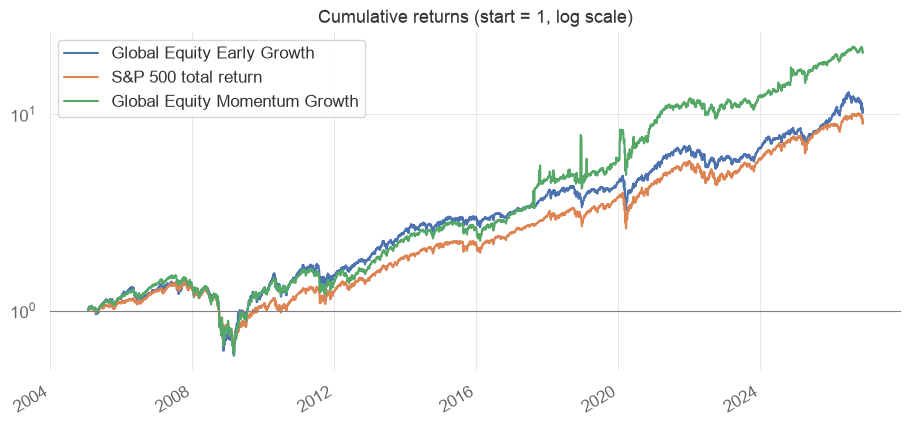

Global Equity Early Growth       10.639303
S&P 500 total return              9.366341
Global Equity Momentum Growth    20.828698
Name: 2026-11-23 00:00:00, dtype: float64

In [12]:
def backtest(weights, prices):
    prices = prices.ffill()  # carry the last close over market holidays, so a holding that does not trade on a rebalance day (e.g. European stocks on 26 December, US stocks on Memorial Day) is not dropped for the month
    dates = list(weights) + [prices.index[-1]]
    parts = []
    for d0, d1 in zip(dates[:-1], dates[1:]):
        w = weights[d0]
        p = prices.loc[d0:d1, w.index].ffill()
        parts.append((p / p.iloc[0]).mul(w, axis=1).sum(axis=1).pct_change().dropna())
    return pd.concat(parts)

fund_r = backtest(holdings, px_ret).rename('Global Equity Early Growth')
bench_holdings = {}
for d in DATES:
    alive = at(pxf, d).reindex(UNIVERSE).dropna().index
    bench_holdings[d] = pd.Series(1 / len(alive), index=alive)
bench_r = backtest(bench_holdings, px_ret).rename('Global Equity Momentum Growth')

def fetch_sp500():
    return yf.download('^SP500TR', start=HISTORY_START, auto_adjust=True, progress=False)['Close']

sp500 = cached('sp500', fetch_sp500).iloc[:, 0]
sp500_r = sp500.reindex(px.index.union(sp500.index)).ffill().pct_change().reindex(fund_r.index).rename('S&P 500 total return')

cum = (1 + pd.concat([fund_r, sp500_r, bench_r], axis=1)).cumprod()
cum = pd.concat([pd.DataFrame(1.0, index=[DATES[0]], columns=cum.columns), cum])
ax = cum.plot(figsize=(11, 5), logy=True, title='Cumulative returns (start = 1, log scale)')
ax.axhline(1, color='grey', lw=0.8)
plt.show()
cum.iloc[-1]

## Risk-free rate: 12-month EURIBOR

European Central Bank Data Portal series `FM.M.U2.EUR.RT.MM.EURIBOR1YD_.HSTA` (monthly average, percent per annum), applied to every trading day of its month. quantstats converts it to a daily rate, $r_{f,d} = (1 + r_{f})^{1/252} - 1$, for the excess-return ratios; cumulative returns stay gross.

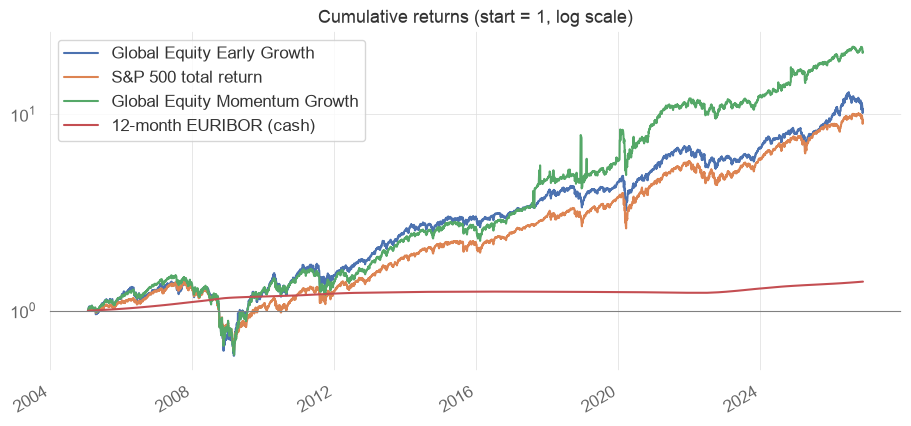

,Average 12-month EURIBOR,Minimum,Maximum
0,0.0155,-0.005,0.0539


In [13]:
ECB_URL = 'https://data-api.ecb.europa.eu/service/data/FM/M.U2.EUR.RT.MM.EURIBOR1YD_.HSTA?format=csvdata&startPeriod=2003-12'

def fetch_euribor():
    raw = pd.read_csv(ECB_URL)
    return raw.set_index(pd.to_datetime(raw['TIME_PERIOD']))[['OBS_VALUE']].rename(columns={'OBS_VALUE': 'euribor_12m'})

euribor = cached('euribor_12m', fetch_euribor)['euribor_12m'] / 100
rf = euribor.reindex(euribor.index.union(fund_r.index)).ffill().reindex(fund_r.index)
cash_r = ((1 + rf) ** (1 / 252) - 1).rename('12-month EURIBOR (cash)')

cum = (1 + pd.concat([fund_r, sp500_r, bench_r, cash_r], axis=1)).cumprod()
cum = pd.concat([pd.DataFrame(1.0, index=[DATES[0]], columns=cum.columns), cum])
ax = cum.plot(figsize=(11, 5), logy=True, title='Cumulative returns (start = 1, log scale)')
ax.axhline(1, color='grey', lw=0.8)
plt.show()
pd.DataFrame({'Average 12-month EURIBOR': [rf.mean()], 'Minimum': [rf.min()], 'Maximum': [rf.max()]}).round(4)

In [14]:
strategies = pd.concat([fund_r, bench_r], axis=1)
m = qs.reports.metrics(strategies, benchmark=sp500_r, rf=rf, mode='full', display=False)
m.loc['Treynor Ratio'] = qs.reports.metrics(strategies, benchmark=sp500_r, rf=float(rf.mean()), mode='full', display=False).loc['Treynor Ratio']
m

,Benchmark,Global Equity Early Growth,Global Equity Momentum Growth
Start Period,2005-01-26,2005-01-26,2005-01-26
End Period,2026-11-23,2026-11-23,2026-11-23
Risk-Free Rate,1.55,1.55,1.55
Time in Market,0.98,1.0,1.0
Cumulative Return,8.37,9.64,19.83
...,...,...,...
Win Year,0.86,0.82,0.77
Beta,-,0.93,0.94
Alpha,-,0.01,0.07
Correlation,-,0.9%,0.58%


## 7. Persona tests

Value-at-risk-equivalent volatility (Commission Delegated Regulation (EU) 2017/653, Annex II), with $\sigma$, $\mu_1$ (skewness) and $\mu_2$ (excess kurtosis) of daily log returns, $N = 256\,T$ trading days over the recommended holding period $T$:
$$\text{VaR}_{\text{return}} = \sigma\sqrt{N}\left(-1.96 + 0.474\frac{\mu_1}{\sqrt{N}} - 0.0687\frac{\mu_2}{N} + 0.146\frac{\mu_1^2}{N}\right) - 0.5\,\sigma^2 N, \qquad \text{VEV} = \frac{\sqrt{3.842 - 2\,\text{VaR}_{\text{return}}} - 1.96}{\sqrt{T}}$$

In [15]:
def vev(r, T=RHP_YEARS):
    x = np.log1p(r.dropna())
    s, m1, m2, N = x.std(), x.skew(), x.kurt(), 256 * T
    var = s * np.sqrt(N) * (-1.96 + 0.474 * m1 / np.sqrt(N) - 0.0687 * m2 / N + 0.146 * m1**2 / N) - 0.5 * s**2 * N
    return (np.sqrt(3.842 - 2 * var) - 1.96) / np.sqrt(T)

def persona_tests(r):
    mdd, v = qs.stats.max_drawdown(r), vev(r)
    return pd.DataFrame({
        'value': [mdd, v, qs.stats.volatility(r), qs.stats.value_at_risk(r)],
        'target': [f'>= {MDD_LIMIT:.0%}', f'{VEV_RANGE[0]:.0%} to {VEV_RANGE[1]:.0%}', 'reference', 'reference (daily, 95%)'],
        'pass': [mdd >= MDD_LIMIT, VEV_RANGE[0] <= v <= VEV_RANGE[1], None, None]},
        index=['Maximum drawdown', 'Value-at-risk-equivalent volatility', 'Annualised volatility', 'Historical value at risk'])

tests = persona_tests(fund_r)
print('Persona conditions met:', bool(tests['pass'].dropna().all()))
pd.concat({'Global Equity Early Growth': tests, 'S&P 500 total return': persona_tests(sp500_r), 'Global Equity Momentum Growth': persona_tests(bench_r)}, axis=1)

Persona conditions met: False


Global Equity Early Growth  \
                                                         value   
Maximum drawdown                                     -0.581985   
Value-at-risk-equivalent volatility                   0.196850   
Annualised volatility                                 0.194408   
Historical value at risk                             -0.019650   

                                                                    \
                                                     target   pass   
Maximum drawdown                                    >= -35%  False   
Value-at-risk-equivalent volatility              12% to 20%   True   
Annualised volatility                             reference   None   
Historical value at risk             reference (daily, 95%)   None   

                                    S&P 500 total return  \
                                                   value   
Maximum drawdown                               -0.552502   
Value-at-risk-equivalent volatility             0.189752   
Annualised volatility                           0.187696   
Historical value at risk                       -0.018982   

                                                                    \
                                                     target   pass   
Maximum drawdown                                    >= -35%  False   
Value-at-risk-equivalent volatility              12% to 20%   True   
Annualised volatility                             reference   None   
Historical value at risk             reference (daily, 95%)   None   

                                    Global Equity Momentum Growth  \
                                                            value   
Maximum drawdown                                        -0.606558   
Value-at-risk-equivalent volatility                      0.299084   
Annualised volatility                                    0.303712   
Historical value at risk                                -0.030757   

                                                                    
                                                     target   pass  
Maximum drawdown                                    >= -35%  False  
Value-at-risk-equivalent volatility              12% to 20%  False  
Annualised volatility                             reference   None  
Historical value at risk             reference (daily, 95%)   None

## 8. Backtest analysis

Monthly holdings, trading costs and the performance measures required by the brief. Assumptions used in every table and figure of this section:

| Item | Assumption |
|---|---|
| Return frequency | Monthly returns, compounded from daily returns within each calendar month (the first and last months are partial). Daily fund and S&P 500 returns are not synchronous (European and United States markets close at different times and have different holidays), which biases daily beta and correlation downwards; set `FREQ = 'D'` to check robustness |
| Annualisation | Arithmetic mean × 12 and volatility × √12; the compound (geometric) return over the whole period is also shown; beta is not annualised |
| Risk-free rate | 12-month EURIBOR (European Central Bank), converted to a daily rate and compounded within each month like the portfolio |
| Sharpe ratio | Annualised mean excess return over the risk-free rate / annualised volatility of excess returns |
| Alpha and beta | Ordinary least squares regression of monthly fund excess returns on benchmark excess returns; alpha × 12, with its t-statistic |
| Information ratio | Annualised mean active return (fund − benchmark) / annualised tracking error (volatility of active returns × √12) |
| Transaction costs | `COST_BPS` per euro traded, charged inside each fund at each rebalance including the initial purchase. Trades = target weight − weight drifted with prices since the previous rebalance |
| Management fee | Accrued daily on net asset value by calendar time, $(1 - m)^{\Delta t / 365.25}$, so a full year costs exactly $m$ |
| Entry and exit fees | Charged on the investor's money, not inside the fund: they appear in the wealth-per-euro tables (8.2), not in return series, ratios, drawdowns or persona tests, as in key information documents |
| Benchmark | S&P 500 total return. Relative measures in Table 8.3b compare each Global Equity Early Growth class with the same Global Equity Momentum Growth class |

The quantstats table in Section 6 uses other definitions (for example, its information ratio is not annualised and its alpha is not estimated on excess returns), so the prospectus reports the tables below.

In [16]:
# 8.0 Data check: largest daily price move of each universe stock (moves above ±50% are usually bad yfinance data)
p = pxr[UNIVERSE]
moves = (p / p.shift(1) - 1).fillna(0.0)
worst = moves.abs().idxmax()
check = pd.DataFrame({'largest daily move': [moves.loc[d, t] for t, d in worst.items()],
                      'date': worst.values, 'region': REGION.reindex(worst.index).values}, index=worst.index)
print(f'{(moves.abs() > 0.5).any().sum()} of {len(UNIVERSE)} universe stocks have at least one daily move above ±50%')
check.loc[check['largest daily move'].abs().sort_values(ascending=False).index].head(15)

52 of 400 universe stocks have at least one daily move above ±50%


,largest daily move,date,region
ESINQ,99.000000,2017-08-24,US
ATO.PA,85.278784,2024-11-12,EU
LOCAL.PA,23.000000,2024-07-05,EU
ARO.DU,4.000000,2018-06-04,EU
MFEB.MI,3.671404,2023-10-24,EU
RGS,3.047337,2024-06-25,US
GR,1.666667,2013-11-20,US
NKTR,1.562893,2025-06-24,US
AC.PA,1.335104,2004-01-22,EU
FMCC,1.283784,2009-08-10,US


In [17]:
# 8.1 Monthly holdings: target weights set at each rebalance and the weights just before it
def drifted_weights(weights, prices):
    """Weight of each holding at the next rebalance date, before trading, after drifting with prices."""
    prices = prices.ffill()  # carry the last close over market holidays, as in backtest()
    dates = list(weights)
    pre = {dates[0]: pd.Series(dtype=float)}  # nothing is held before the first purchase
    for d0, d1 in zip(dates[:-1], dates[1:]):
        w = weights[d0]
        p = prices.loc[d0:d1, w.index]
        v = w * p.iloc[-1] / p.iloc[0]
        pre[d1] = v / v.sum()
    return pd.DataFrame(pre).T

W = pd.DataFrame(holdings).T.fillna(0.0)  # rows: rebalance dates, columns: tickers
W_pre = drifted_weights(holdings, px_ret).reindex(index=W.index, columns=W.columns).fillna(0.0)
trades = W - W_pre                        # + bought, − sold, as a share of portfolio value
traded = trades.abs().sum(axis=1)         # buys + sells (first rebalance: initial purchase = 100%)
orders = (trades.abs() > 1e-6).sum(axis=1)

rows = []
for d in W.index:
    names = W.columns[(W.loc[d] > 0) | (W_pre.loc[d] > 0)]
    rows.append(pd.DataFrame({'date': d, 'ticker': names, 'region': REGION.reindex(names).values,
                              'weight before': W_pre.loc[d, names].values, 'target weight': W.loc[d, names].values}))
holdings_long = pd.concat(rows, ignore_index=True)  # full month-by-month list (also usable by the app)
holdings_long['action'] = np.select([holdings_long['weight before'] == 0, holdings_long['target weight'] == 0],
                                    ['enter', 'exit'], 'keep')

us = REGION.reindex(W.columns).eq('US').values
holdings_summary = pd.DataFrame({'holdings': (W > 0).sum(axis=1), 'United States weight': W.loc[:, us].sum(axis=1),
                                 'Europe weight': W.loc[:, ~us].sum(axis=1), 'traded (buys + sells)': traded,
                                 'orders': orders})
print(f'{len(W)} rebalances; holdings at the latest one ({W.index[-1]:%Y-%m-%d}):')
holdings_long[holdings_long['date'] == W.index[-1]].sort_values(['action', 'ticker'])

W_b = pd.DataFrame(bench_holdings).T.fillna(0.0)
W_b_pre = drifted_weights(bench_holdings, px_ret).reindex(index=W_b.index, columns=W_b.columns).fillna(0.0)
traded_b = (W_b - W_b_pre).abs().sum(axis=1)  # Global Equity Momentum Growth: rebalancing back to equal weights

262 rebalances; holdings at the latest one (2026-10-26):


In [18]:
# Monthly summary (holdings count, regional split, trading); the full list is in `holdings_long`
holdings_summary.round(3)

,holdings,United States weight,Europe weight,traded (buys + sells),orders
2005-01-25,50,0.88,0.12,1.000,50
2005-02-25,50,0.88,0.12,0.128,52
2005-03-25,50,0.86,0.14,0.270,56
2005-04-25,50,0.82,0.18,0.319,57
2005-05-25,50,0.82,0.18,0.171,53
...,...,...,...,...,...
2026-06-25,50,0.84,0.16,0.167,52
2026-07-27,50,0.84,0.16,0.105,50
2026-08-25,50,0.86,0.14,0.149,52
2026-09-25,50,0.88,0.12,0.190,53


In [19]:
# 8.2 Transaction costs and share classes. COST_BPS is a PLACEHOLDER the group must set and justify (decisions log: still open)
COST_BPS = 10        # proportional cost per euro traded, in basis points (bid-ask spread and commission)
CAPITAL = 3_000      # client's initial investment in euros (decisions log: €2,500–€3,000)
HOLD_YEARS = 20
ENTRY_E, MGMT_E = 0.03, 0.015
EXIT_G = 0.01

def after_costs(r, traded, bps=COST_BPS):
    """Daily returns after bps × value traded at each rebalance (initial purchase: first return day)."""
    day = [r.index[r.index >= d][0] for d in traded.index]
    c = pd.Series(traded.values * bps / 1e4, index=day).groupby(level=0).sum().reindex(r.index, fill_value=0.0)
    return (1 + r) * (1 - c) - 1

def after_fees(r, mgmt):
    """Daily returns after a management fee accrued by calendar time on net asset value."""
    days = r.index.to_series().diff().dt.days
    days.iloc[0] = (r.index[0] - DATES[0]).days
    return (1 + r) * (1 - mgmt) ** (days / 365.25) - 1

mgmt_F = 1 - (1 - ENTRY_E) ** (1 / HOLD_YEARS) * (1 - MGMT_E)
mgmt_G = 1 - ((1 - ENTRY_E) / (1 - EXIT_G)) ** (1 / HOLD_YEARS) * (1 - MGMT_E)
CLASSES = pd.DataFrame({'entry fee': [ENTRY_E, 0.0, 0.0], 'management fee': [MGMT_E, mgmt_F, mgmt_G],
                        'exit fee': [0.0, 0.0, EXIT_G]}, index=['E', 'F', 'G'])
CLASSES[f'{HOLD_YEARS}-year wealth per euro, fees only'] = ((1 - CLASSES['entry fee']) * (1 - CLASSES['management fee']) ** HOLD_YEARS
                                                       * (1 - CLASSES['exit fee']))

gross = {'Global Equity Early Growth': fund_r, 'Global Equity Momentum Growth': bench_r}
turnover = {'Global Equity Early Growth': traded, 'Global Equity Momentum Growth': traded_b}
net = {f: after_costs(gross[f], turnover[f]) for f in gross}
nav = {f'{f} {k}': after_fees(net[f], CLASSES.loc[k, 'management fee']) for f in gross for k in CLASSES.index}

years = (fund_r.index[-1] - DATES[0]).days / 365.25
for f in gross:
    drag = (1 + gross[f]).prod() ** (1 / years) - (1 + net[f]).prod() ** (1 / years)
    print(f'{f}: one-way turnover {turnover[f].iloc[1:].sum() / 2 / years:.0%} per year, '
          f'transaction cost drag {drag:.2%} per year at {COST_BPS} bps')
CLASSES.style.format('{:.4%}', subset=['entry fee', 'management fee', 'exit fee']).format('{:.4f}', subset=CLASSES.columns[-1])

Global Equity Early Growth: one-way turnover 166% per year, transaction cost drag 0.37% per year at 10 bps
Global Equity Momentum Growth: one-way turnover 38% per year, transaction cost drag 0.09% per year at 10 bps


/var/folders/5f/4jq9lvvj6732d28vk6bvy7_c0000gn/T/ipykernel_93868/902856425.py:17: SettingWithCopyWarning: modifications to a property of a datetimelike object are not supported and are discarded. Change values on the original.
  days.iloc[0] = (r.index[0] - DATES[0]).days


,entry fee,management fee,exit fee,"20-year wealth per euro, fees only"
E,3.0000%,1.5000%,0.0000%,0.7170
F,0.0000%,1.6499%,0.0000%,0.7170
G,0.0000%,1.6005%,1.0000%,0.7170


**Share-class equivalence.** All fees are proportional to value, so for any return path the wealth per euro after $T$ years is
$$W_k = (1 - e_k)\,(1 - m_k)^{T}\,(1 - x_k)\,\prod_d (1 + r_d),$$
with entry fee $e_k$, management fee $m_k$, exit fee $x_k$ and fund returns after transaction costs $r_d$. Setting $W_F = W_G = W_E$ over $T = 20$ years gives
$$1 - m_F = (1 - e_E)^{1/T}(1 - m_E), \qquad 1 - m_G = \left(\frac{1 - e_E}{1 - x_G}\right)^{1/T}(1 - m_E).$$
The equality holds for every holding of exactly 20 years; shorter holdings favour E less (the entry fee is paid up front), longer ones favour it more.

In [20]:
# Wealth per euro invested, including entry and exit fees: 20-year holding from fund creation, and the full backtest
def wealth_per_euro(name, end):
    k = name[-1]
    return (1 - CLASSES.loc[k, 'entry fee']) * (1 + nav[name].loc[:end]).prod() * (1 - CLASSES.loc[k, 'exit fee'])

end_20 = DATES[0] + pd.DateOffset(years=HOLD_YEARS)
wealth_table = pd.DataFrame({(f, k): [wealth_per_euro(f'{f} {k}', end_20), wealth_per_euro(f'{f} {k}', fund_r.index[-1])]
                       for f in gross for k in CLASSES.index},
                      index=[f'{HOLD_YEARS} years ({DATES[0]:%Y-%m-%d} to {end_20:%Y-%m-%d})',
                             f'Full backtest ({DATES[0]:%Y-%m-%d} to {fund_r.index[-1]:%Y-%m-%d})'])
print(f'Wealth per euro invested; × {CAPITAL:,} for the client\'s euros')
wealth_table.round(4)

Wealth per euro invested; × 3,000 for the client's euros


Global Equity Early Growth          \
                                                                  E       F   
20 years (2005-01-25 to 2025-01-25)                          5.5911  5.5912   
Full backtest (2005-01-25 to 2026-11-23)                     6.8946  6.8754   

                                                  \
                                               G   
20 years (2005-01-25 to 2025-01-25)       5.5912   
Full backtest (2005-01-25 to 2026-11-23)  6.8818   

                                         Global Equity Momentum Growth  \
                                                                     E   
20 years (2005-01-25 to 2025-01-25)                            11.7395   
Full backtest (2005-01-25 to 2026-11-23)                       14.2722   

                                                            
                                                F        G  
20 years (2005-01-25 to 2025-01-25)       11.7395  11.7395  
Full backtest (2005-01-25 to 2026-11-23)  14.2325  14.2456

In [21]:
# 8.3 Performance measures required by the brief (Tables 8.3a and 8.3b); assumptions at the top of Section 8
import statsmodels.api as sm

FREQ = 'M'  # 'M' monthly (reported) or 'D' daily (robustness check)
PERIODS = {'D': 252, 'M': 12}
PCT = ['Annualised average return (arithmetic)', 'Annualised compound return (geometric)', 'Annualised volatility',
       'Alpha (annualised)', 'Tracking error (annualised)', 'Maximum drawdown (daily)']
RELATIVE = ['Alpha (annualised)', 'Alpha t-statistic', 'Beta (not annualised)', 'Tracking error (annualised)', 'Information ratio']

def performance(r, bench, rf=cash_r, freq=FREQ):
    """Brief's measures for one daily return series against one benchmark (rf: daily risk-free return)."""
    k = PERIODS[freq]
    daily = pd.concat({'p': r, 'b': bench, 'rf': rf}, axis=1).dropna()
    df = daily if freq == 'D' else (1 + daily).resample('ME').prod() - 1
    ex, ex_b, active = df['p'] - df['rf'], df['b'] - df['rf'], df['p'] - df['b']
    same = active.abs().max() < 1e-12  # the benchmark measured against itself
    fit = None if same else sm.OLS(ex, sm.add_constant(ex_b)).fit()
    te = active.std() * np.sqrt(k)
    wealth = (1 + daily['p']).cumprod()
    years = (daily.index[-1] - daily.index[0]).days / 365.25
    return pd.Series({
        'Annualised average return (arithmetic)': df['p'].mean() * k,
        'Annualised compound return (geometric)': wealth.iloc[-1] ** (1 / years) - 1,
        'Annualised volatility': df['p'].std() * np.sqrt(k),
        'Sharpe ratio': ex.mean() / ex.std() * np.sqrt(k),
        'Alpha (annualised)': 0.0 if same else fit.params.iloc[0] * k,
        'Alpha t-statistic': np.nan if same else fit.tvalues.iloc[0],
        'Beta (not annualised)': 1.0 if same else fit.params.iloc[1],
        'Tracking error (annualised)': te,
        'Information ratio': np.nan if same else active.mean() * k / te,
        'Maximum drawdown (daily)': (wealth / wealth.cummax().clip(lower=1) - 1).min(),
    })

def fmt(t):
    return pd.DataFrame([['–' if pd.isna(x) else f'{x:.2%}' if i in PCT else f'{x:.2f}' for x in t.loc[i]] for i in t.index],
                        index=t.index, columns=t.columns)

series = {'S&P 500 total return': sp500_r}
for f in gross:
    series[f'{f} gross'] = gross[f]
    for k in CLASSES.index:
        series[f'{f} {k}'] = nav[f'{f} {k}']
table_sp = pd.DataFrame({n: performance(s, sp500_r) for n, s in series.items()})
table_rel = pd.DataFrame({f'Global Equity Early Growth {k}': performance(nav[f'Global Equity Early Growth {k}'], nav[f'Global Equity Momentum Growth {k}']) for k in CLASSES.index}).loc[RELATIVE]
freq_label = 'monthly' if FREQ == 'M' else 'daily'
print(f'Table 8.3a: measures against the S&P 500 total return ({freq_label} returns, '
      f'{fund_r.index[0]:%Y-%m-%d} to {fund_r.index[-1]:%Y-%m-%d}); share classes after transaction costs and management fees')
display(fmt(table_sp))
print(f'Table 8.3b: relative measures of each Global Equity Early Growth class against the same Global Equity Momentum Growth class')
display(fmt(table_rel))


Table 8.3a: measures against the S&P 500 total return (monthly returns, 2005-01-26 to 2026-11-23); share classes after transaction costs and management fees


,S&P 500 total return,Global Equity Early Growth gross,Global Equity Early Growth E,Global Equity Early Growth F,Global Equity Early Growth G,Global Equity Momentum Growth gross,Global Equity Momentum Growth E,Global Equity Momentum Growth F,Global Equity Momentum Growth G
Annualised average return (arithmetic),11.35%,12.47%,10.62%,10.46%,10.51%,15.86%,14.26%,14.10%,14.15%
Annualised compound return (geometric),10.79%,11.44%,9.40%,9.24%,9.29%,14.93%,13.11%,12.94%,13.00%
Annualised volatility,14.79%,18.10%,18.09%,18.09%,18.09%,19.98%,19.94%,19.94%,19.94%
Sharpe ratio,0.66,0.60,0.50,0.49,0.49,0.71,0.63,0.63,0.63
Alpha (annualised),0.00%,0.36%,-1.50%,-1.65%,-1.60%,3.72%,2.13%,1.98%,2.03%
Alpha t-statistic,–,0.19,-0.80,-0.88,-0.86,1.42,0.81,0.76,0.78
Beta (not annualised),1.00,1.08,1.08,1.08,1.08,1.08,1.08,1.08,1.08
Tracking error (annualised),0.00%,8.65%,8.63%,8.63%,8.63%,12.09%,12.06%,12.06%,12.06%
Information ratio,–,0.13,-0.09,-0.10,-0.10,0.37,0.24,0.23,0.23
Maximum drawdown (daily),-55.25%,-58.20%,-59.60%,-59.71%,-59.67%,-60.66%,-61.76%,-61.86%,-61.82%


Table 8.3b: relative measures of each Global Equity Early Growth class against the same Global Equity Momentum Growth class


,Global Equity Early Growth E,Global Equity Early Growth F,Global Equity Early Growth G
Alpha (annualised),0.08%,0.03%,0.05%
Alpha t-statistic,0.03,0.01,0.02
Beta (not annualised),0.71,0.71,0.71
Tracking error (annualised),12.78%,12.78%,12.78%
Information ratio,-0.28,-0.28,-0.28


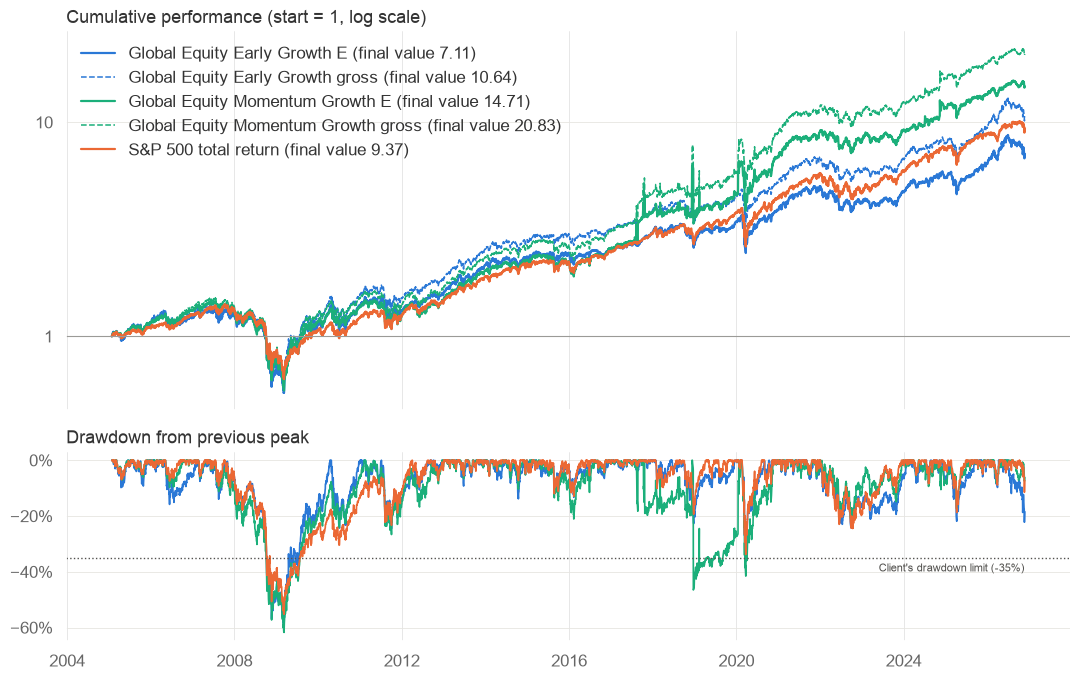

In [22]:
# 8.4 Figure: cumulative performance (start = 1, net asset value of class E; F and G differ only by their management fee) and drawdowns
from matplotlib.ticker import FuncFormatter, NullFormatter, PercentFormatter

STYLE = {'Global Equity Early Growth E': ('#2a78d6', '-'), 'Global Equity Early Growth gross': ('#2a78d6', '--'),
         'Global Equity Momentum Growth E': ('#1baf7a', '-'), 'Global Equity Momentum Growth gross': ('#1baf7a', '--'),
         'S&P 500 total return': ('#eb6834', '-')}
lines = pd.concat({n: series[n] for n in STYLE}, axis=1).dropna()
wealth = pd.concat([pd.DataFrame(1.0, index=[DATES[0]], columns=lines.columns), (1 + lines).cumprod()])
drawdown = wealth / wealth.cummax() - 1

fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
for name, (color, ls) in STYLE.items():
    a1.plot(wealth.index, wealth[name], color=color, ls=ls, lw=1.6 if ls == '-' else 1.1,
            label=f'{name} (final value {wealth[name].iloc[-1]:.2f})')
    if not name.endswith('gross'):
        a2.plot(drawdown.index, drawdown[name], color=color, lw=1.2)
a1.set_yscale('log')
a1.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f'{y:g}'))
a1.yaxis.set_minor_formatter(NullFormatter())
a1.axhline(1, color='#9b9a97', lw=0.8)
a1.set_title('Cumulative performance (start = 1, log scale)', loc='left')
a1.legend(frameon=False, loc='upper left')
a2.axhline(MDD_LIMIT, color='#52514e', ls=':', lw=1)
a2.annotate(f"Client's drawdown limit ({MDD_LIMIT:.0%})", (drawdown.index[-1], MDD_LIMIT), xytext=(0, -4),
            textcoords='offset points', ha='right', va='top', fontsize=8, color='#52514e')
a2.set_title('Drawdown from previous peak', loc='left')
a2.yaxis.set_major_formatter(PercentFormatter(1))
for a in (a1, a2):
    a.grid(axis='y', color='#e6e5e1', lw=0.6)
    a.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

In [23]:
# 8.5 Calendar-year returns (Table 8.5), class E net asset value; 2005 and 2026 are partial years
cal = pd.concat({n: series[n] for n in ['Global Equity Early Growth E', 'Global Equity Momentum Growth E', 'S&P 500 total return']}, axis=1).dropna()
yearly = (1 + cal).groupby(cal.index.year).prod() - 1
yearly['Early Growth E − S&P 500'] = yearly['Global Equity Early Growth E'] - yearly['S&P 500 total return']
print(f"Global Equity Early Growth E beat the S&P 500 in {(yearly['Early Growth E − S&P 500'] > 0).sum()} of {len(yearly)} calendar years")
yearly.map(lambda x: f'{x:.1%}')

Global Equity Early Growth E beat the S&P 500 in 9 of 22 calendar years


,Global Equity Early Growth E,Global Equity Momentum Growth E,S&P 500 total return,Early Growth E − S&P 500
Date,,,,
2005,13.2%,13.9%,8.7%,4.4%
2006,8.3%,16.2%,15.8%,-7.5%
2007,3.2%,-0.8%,5.5%,-2.3%
2008,-44.1%,-40.5%,-37.0%,-7.1%
2009,59.0%,49.2%,26.5%,32.5%
2010,23.3%,17.2%,15.1%,8.2%
2011,-4.8%,-9.0%,2.1%,-6.9%
2012,19.5%,17.8%,16.0%,3.5%
2013,37.0%,39.5%,32.4%,4.6%


In [24]:
# 8.6 Cost sensitivity (Table 8.6): transaction cost levels by share class, Global Equity Early Growth, against the S&P 500 total return
grid = []
for bps in (0, 10, 25, 50):
    for k in CLASSES.index:
        r = after_fees(after_costs(fund_r, traded, bps=bps), CLASSES.loc[k, 'management fee'])
        m = performance(r, sp500_r)
        grid.append({'cost per euro traded (bps)': bps, 'class': k,
                     'compound return': m['Annualised compound return (geometric)'], 'Sharpe ratio': m['Sharpe ratio'],
                     'alpha': m['Alpha (annualised)'], 'information ratio': m['Information ratio'],
                     f'{HOLD_YEARS}-year wealth per euro': (1 - CLASSES.loc[k, 'entry fee']) * (1 + r.loc[:end_20]).prod()
                                                        * (1 - CLASSES.loc[k, 'exit fee'])})
pd.DataFrame(grid).set_index(['cost per euro traded (bps)', 'class']).style.format(
    {'compound return': '{:.2%}', 'alpha': '{:.2%}', 'Sharpe ratio': '{:.2f}', 'information ratio': '{:.2f}',
     f'{HOLD_YEARS}-year wealth per euro': '{:.4f}'})

/var/folders/5f/4jq9lvvj6732d28vk6bvy7_c0000gn/T/ipykernel_93868/902856425.py:17: SettingWithCopyWarning: modifications to a property of a datetimelike object are not supported and are discarded. Change values on the original.
  days.iloc[0] = (r.index[0] - DATES[0]).days
/var/folders/5f/4jq9lvvj6732d28vk6bvy7_c0000gn/T/ipykernel_93868/902856425.py:17: SettingWithCopyWarning: modifications to a property of a datetimelike object are not supported and are discarded. Change values on the original.
  days.iloc[0] = (r.index[0] - DATES[0]).days
/var/folders/5f/4jq9lvvj6732d28vk6bvy7_c0000gn/T/ipykernel_93868/902856425.py:17: SettingWithCopyWarning: modifications to a property of a datetimelike object are not supported and are discarded. Change values on the original.
  days.iloc[0] = (r.index[0] - DATES[0]).days
/var/folders/5f/4jq9lvvj6732d28vk6bvy7_c0000gn/T/ipykernel_93868/902856425.py:17: SettingWithCopyWarning: modifications to a property of a datetimelike object are not supported and 

In [25]:
# 8.7 Persona tests by share class (net asset value after transaction costs and management fees)
by_class = pd.concat({n: persona_tests(r) for n, r in nav.items()}, axis=1)
print('Persona conditions met by every class:', all(by_class.xs('pass', axis=1, level=1).dropna().all()))
by_class

Persona conditions met by every class: False


Global Equity Early Growth E  \
                                                           value   
Maximum drawdown                                       -0.596014   
Value-at-risk-equivalent volatility                     0.196839   
Annualised volatility                                   0.194383   
Historical value at risk                               -0.019719   

                                                                    \
                                                     target   pass   
Maximum drawdown                                    >= -35%  False   
Value-at-risk-equivalent volatility              12% to 20%   True   
Annualised volatility                             reference   None   
Historical value at risk             reference (daily, 95%)   None   

                                    Global Equity Early Growth F  \
                                                           value   
Maximum drawdown                                       -0.597091   
Value-at-risk-equivalent volatility                     0.196840   
Annualised volatility                                   0.194383   
Historical value at risk                               -0.019724   

                                                                    \
                                                     target   pass   
Maximum drawdown                                    >= -35%  False   
Value-at-risk-equivalent volatility              12% to 20%   True   
Annualised volatility                             reference   None   
Historical value at risk             reference (daily, 95%)   None   

                                    Global Equity Early Growth G  \
                                                           value   
Maximum drawdown                                       -0.596736   
Value-at-risk-equivalent volatility                     0.196839   
Annualised volatility                                   0.194383   
Historical value at risk                               -0.019723   

                                                                    \
                                                     target   pass   
Maximum drawdown                                    >= -35%  False   
Value-at-risk-equivalent volatility              12% to 20%   True   
Annualised volatility                             reference   None   
Historical value at risk             reference (daily, 95%)   None   

                                    Global Equity Momentum Growth E  \
                                                              value   
Maximum drawdown                                          -0.617555   
Value-at-risk-equivalent volatility                        0.299081   
Annualised volatility                                      0.303684   
Historical value at risk                                  -0.030816   

                                                                    \
                                                     target   pass   
Maximum drawdown                                    >= -35%  False   
Value-at-risk-equivalent volatility              12% to 20%  False   
Annualised volatility                             reference   None   
Historical value at risk             reference (daily, 95%)   None   

                                    Global Equity Momentum Growth F  \
                                                              value   
Maximum drawdown                                          -0.618581   
Value-at-risk-equivalent volatility                        0.299082   
Annualised volatility                                      0.303681   
Historical value at risk                                  -0.030821   

                                                                    \
                                                     target   pass   
Maximum drawdown                                    >= -35%  False   
Value-at-risk-equivalent volatility              12% to 20%  

## 9. Website export

Writes the data behind the fund pages to `app_data/` at the repository root. Only derived data leaves the notebook: net asset value series, portfolio weights, price-to-book ratios of holdings, company names and industry codes. No raw Compustat financials are exported, so the folder can be committed to the public repository.

In [ ]:
def fetch_names(batch=300):
    import wrds
    db = wrds.Connection(wrds_username=WRDS_USERNAME or None)
    keys, out = list(cu.index), []
    for table in ('comp.company', 'comp.g_company'):
        for i in range(0, len(keys), batch):
            chunk = ','.join(f"'{g}'" for g in keys[i:i + batch])
            out.append(db.raw_sql(f'select gvkey, conm as name, sic from {table} where gvkey in ({chunk})'))
    db.close()
    return pd.concat(out).set_index('gvkey')

try:
    names = cached('compustat_names', fetch_names, dates=False)
except Exception as e:
    print(f'Company names and industry codes not fetched ({type(e).__name__}); exporting without them. Rerun this cell later.')
    names = pd.DataFrame(columns=['name', 'sic'], index=pd.Index([], name='gvkey'))
names.index = names.index.astype(str).str.zfill(6)
names = names[~names.index.duplicated(keep='first')]

root = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
APP = os.path.join(root, 'app_data')
os.makedirs(APP, exist_ok=True)

levels = pd.DataFrame({'sp500': sp500_r, 'euribor_12m': cash_r})
for f, key in (('Global Equity Early Growth', 'early_growth'), ('Global Equity Momentum Growth', 'momentum_growth')):
    levels[f'{key}_gross'] = gross[f]
    for k in CLASSES.index:
        levels[f'{key}_{k}'] = nav[f'{f} {k}']
levels = pd.concat([pd.DataFrame(0.0, index=[DATES[0]], columns=levels.columns), levels])
(1 + levels).cumprod().round(6).to_csv(f'{APP}/nav.csv', index_label='date')

rows = []
for key, weights, dates in (('early_growth', holdings, DATES), ('momentum_growth', bench_holdings, DATES[-12:])):
    for d in dates:
        w = weights[d]
        rows.append(pd.DataFrame({'fund': key, 'date': d.date(), 'ticker': w.index, 'weight': w.values,
                                  'price_to_book': pb(d).reindex(w.index).values}))
pd.concat(rows).round(6).to_csv(f'{APP}/holdings.csv', index=False)

held_ever = sorted(set().union(*[set(w.index) for w in holdings.values()], *[set(bench_holdings[d].index) for d in DATES[-12:]]))
securities = pd.DataFrame({'ticker': held_ever, 'region': REGION.reindex(held_ever).values})
securities['gvkey'] = GVKEY.reindex(held_ever).values
securities = securities.join(names, on='gvkey').drop(columns='gvkey')
securities.to_csv(f'{APP}/securities.csv', index=False)

CLASSES.to_csv(f'{APP}/classes.csv', index_label='class')
pd.Series({'fund_launch': str(DATES[0].date()), 'last_date': str(fund_r.index[-1].date()), 'cost_bps': COST_BPS,
           'hold_years': HOLD_YEARS, 'n_hold': N_HOLD, 'sample': False,
           'generated': pd.Timestamp.now().isoformat(timespec='minutes')}).to_json(f'{APP}/meta.json')
print(f'Exported to {APP}:', sorted(os.listdir(APP)))